# Flagging Vendor invoce for manual review

In [1]:
print('hello')

hello


In [2]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
conn = sqlite3.connect('D:/CodeAIML/python/project/Invoice Intelligence Machine Learning/Data/inventory.db')
table= pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table';", conn)

for t in table['name']:
    print(f'Table: {t}')
    display(pd.read_sql(f'SELECT * FROM {t} LIMIT 5;', conn))

Table: purchases


,InventoryId,Store,Brand,Description,Size,VendorNumber,VendorName,PONumber,PODate,ReceivingDate,InvoiceDate,PayDate,PurchasePrice,Quantity,Dollars,Classification
0,69_MOUNTMEND_8412,69,8412,Tequila Ocho Plata Fresno,750mL,105,ALTAMAR BRANDS LLC,8124,2023-12-21,2024-01-02,2024-01-04,2024-02-16,35.71,6,214.26,1
1,30_CULCHETH_5255,30,5255,TGI Fridays Ultimte Mudslide,1.75L,4466,AMERICAN VINTAGE BEVERAGE,8137,2023-12-22,2024-01-01,2024-01-07,2024-02-21,9.35,4,37.40,1
2,34_PITMERDEN_5215,34,5215,TGI Fridays Long Island Iced,1.75L,4466,AMERICAN VINTAGE BEVERAGE,8137,2023-12-22,2024-01-02,2024-01-07,2024-02-21,9.41,5,47.05,1
3,1_HARDERSFIELD_5255,1,5255,TGI Fridays Ultimte Mudslide,1.75L,4466,AMERICAN VINTAGE BEVERAGE,8137,2023-12-22,2024-01-01,2024-01-07,2024-02-21,9.35,6,56.10,1
4,76_DONCASTER_2034,76,2034,Glendalough Double Barrel,750mL,388,ATLANTIC IMPORTING COMPANY,8169,2023-12-24,2024-01-02,2024-01-09,2024-02-16,21.32,5,106.60,1


Table: purchase_prices


,Brand,Description,Price,Size,Volume,Classification,PurchasePrice,VendorNumber,VendorName
0,58,Gekkeikan Black & Gold Sake,12.99,750mL,750,1,9.28,8320,SHAW ROSS INT L IMP LTD
1,62,Herradura Silver Tequila,36.99,750mL,750,1,28.67,1128,BROWN-FORMAN CORP
2,63,Herradura Reposado Tequila,38.99,750mL,750,1,30.46,1128,BROWN-FORMAN CORP
3,72,No. 3 London Dry Gin,34.99,750mL,750,1,26.11,9165,ULTRA BEVERAGE COMPANY LLP
4,75,Three Olives Tomato Vodka,14.99,750mL,750,1,10.94,7245,PROXIMO SPIRITS INC.


Table: vendor_invoice


,VendorNumber,VendorName,InvoiceDate,PONumber,PODate,PayDate,Quantity,Dollars,Freight,Approval
0,105,ALTAMAR BRANDS LLC,2024-01-04,8124,2023-12-21,2024-02-16,6,214.26,3.47,None
1,4466,AMERICAN VINTAGE BEVERAGE,2024-01-07,8137,2023-12-22,2024-02-21,15,140.55,8.57,None
2,388,ATLANTIC IMPORTING COMPANY,2024-01-09,8169,2023-12-24,2024-02-16,5,106.60,4.61,None
3,480,BACARDI USA INC,2024-01-12,8106,2023-12-20,2024-02-05,10100,137483.78,2935.20,None
4,516,BANFI PRODUCTS CORP,2024-01-07,8170,2023-12-24,2024-02-12,1935,15527.25,429.20,None


Table: begin_inventory


,InventoryId,Store,City,Brand,Description,Size,onHand,Price,startDate
0,1_HARDERSFIELD_58,1,HARDERSFIELD,58,Gekkeikan Black & Gold Sake,750mL,8,12.99,2024-01-01
1,1_HARDERSFIELD_60,1,HARDERSFIELD,60,Canadian Club 1858 VAP,750mL,7,10.99,2024-01-01
2,1_HARDERSFIELD_62,1,HARDERSFIELD,62,Herradura Silver Tequila,750mL,6,36.99,2024-01-01
3,1_HARDERSFIELD_63,1,HARDERSFIELD,63,Herradura Reposado Tequila,750mL,3,38.99,2024-01-01
4,1_HARDERSFIELD_72,1,HARDERSFIELD,72,No. 3 London Dry Gin,750mL,6,34.99,2024-01-01


Table: end_inventory


,InventoryId,Store,City,Brand,Description,Size,onHand,Price,endDate
0,1_HARDERSFIELD_58,1,HARDERSFIELD,58,Gekkeikan Black & Gold Sake,750mL,11,12.99,2024-12-31
1,1_HARDERSFIELD_62,1,HARDERSFIELD,62,Herradura Silver Tequila,750mL,7,36.99,2024-12-31
2,1_HARDERSFIELD_63,1,HARDERSFIELD,63,Herradura Reposado Tequila,750mL,7,38.99,2024-12-31
3,1_HARDERSFIELD_72,1,HARDERSFIELD,72,No. 3 London Dry Gin,750mL,4,34.99,2024-12-31
4,1_HARDERSFIELD_75,1,HARDERSFIELD,75,Three Olives Tomato Vodka,750mL,7,14.99,2024-12-31


In [4]:
purchase_order = pd.read_sql('SELECT * FROM purchases;', conn)
purchase_order.columns

Index(['InventoryId', 'Store', 'Brand', 'Description', 'Size', 'VendorNumber',
       'VendorName', 'PONumber', 'PODate', 'ReceivingDate', 'InvoiceDate',
       'PayDate', 'PurchasePrice', 'Quantity', 'Dollars', 'Classification'],
      dtype='object')

In [5]:
df= pd.read_sql_query("""select p.PONumber, count(distinct p.Brand) as total_brands, sum(p.Quantity) as total_Quantity, sum(p.Dollars) as total_item_dollars, avg(julianday(p.ReceivingDate) - julianday(p.PODate)) as avg_days_to_receive from purchases p group by p.PONumber """, conn)

In [6]:
pd.read_sql_query(""" select v.Quantity as invoice_quantity, v.Dollars as invoice_dollars, v.Freight as invoice_freight, (julianday(v.InvoiceDate)- julianday(v.PODate)) as days_to_receive , (julianday(v.PayDate)- julianday(v.InvoiceDate)) as days_to_pay from vendor_invoice v
""",conn)

,invoice_quantity,invoice_dollars,invoice_freight,days_to_receive,days_to_pay
0,6,214.26,3.47,14.0,43.0
1,15,140.55,8.57,16.0,45.0
2,5,106.60,4.61,16.0,38.0
3,10100,137483.78,2935.20,23.0,24.0
4,1935,15527.25,429.20,14.0,36.0
...,...,...,...,...,...
5538,90,1563.00,8.60,16.0,35.0
5539,4617,37300.48,186.50,18.0,39.0
5540,9848,202815.78,932.95,11.0,33.0
5541,24747,149007.56,819.54,14.0,36.0


In [7]:
data=pd.read_sql_query("""
    WITH df AS (
        SELECT p.PONumber, count(distinct p.Brand) as total_brands, sum(p.Quantity) as total_Quantity, sum(p.Dollars) as total_item_dollars, avg(julianday(p.ReceivingDate) - julianday(p.PODate)) as avg_days_to_receive from purchases p group by p.PONumber
    )
    SELECT
        v.PONumber,
        v. Quantity AS invoice_quantity,
        v. Dollars AS invoice_dollars,
        v.Freight,
        (julianday(v.InvoiceDate) - julianday (v.PODate)) AS days_po_to_invoice,
        (julianday(v. PayDate) - julianday (v.InvoiceDate)) AS days_to_pay,
        pa.total_brands,
        pa.total_Quantity,
        pa.total_item_dollars,
        pa.avg_days_to_receive

        FROM vendor_invoice v
        LEFT JOIN df pa
        ON v.PONumber = pa.PONumber
""",conn)

In [8]:
data.head(5)

,PONumber,invoice_quantity,invoice_dollars,Freight,days_po_to_invoice,days_to_pay,total_brands,total_Quantity,total_item_dollars,avg_days_to_receive
0,8124,6,214.26,3.47,14.0,43.0,1,6,214.26,12.000000
1,8137,15,140.55,8.57,16.0,45.0,2,15,140.55,10.333333
2,8169,5,106.60,4.61,16.0,38.0,1,5,106.60,9.000000
3,8106,10100,137483.78,2935.20,23.0,24.0,81,10100,137483.78,12.614130
4,8170,1935,15527.25,429.20,14.0,36.0,29,1935,15527.25,8.752809


In [9]:
data.isnull().sum()

PONumber               0
invoice_quantity       0
invoice_dollars        0
Freight                0
days_po_to_invoice     0
days_to_pay            0
total_brands           0
total_Quantity         0
total_item_dollars     0
avg_days_to_receive    0
dtype: int64

In [12]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5543 entries, 0 to 5542
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   PONumber             5543 non-null   int64  
 1   invoice_quantity     5543 non-null   int64  
 2   invoice_dollars      5543 non-null   float64
 3   Freight              5543 non-null   float64
 4   days_po_to_invoice   5543 non-null   float64
 5   days_to_pay          5543 non-null   float64
 6   total_brands         5543 non-null   int64  
 7   total_Quantity       5543 non-null   int64  
 8   total_item_dollars   5543 non-null   float64
 9   avg_days_to_receive  5543 non-null   float64
dtypes: float64(6), int64(4)
memory usage: 433.2 KB


In [10]:
def create_label(row):
    if (abs(row['invoice_dollars']-row['total_item_dollars'])>5):
        return 1
    if row['avg_days_to_receive']>10:
        return 1
    return 0
data['flag_invoice'] = data.apply(create_label, axis=1)
data['flag_invoice'].value_counts()

flag_invoice
0    3693
1    1850
Name: count, dtype: int64

<Axes: title={'center': 'Flagged vs Non-Flagged Invoices'}, xlabel='flag_invoice'>

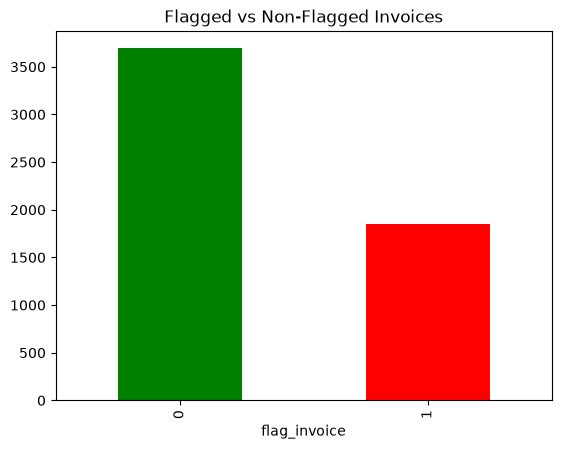

In [11]:
data['flag_invoice'].value_counts().plot(kind='bar', title='Flagged vs Non-Flagged Invoices', color=['green', 'red'])

Text(0.5, 1.0, 'Correlation Heatmap')

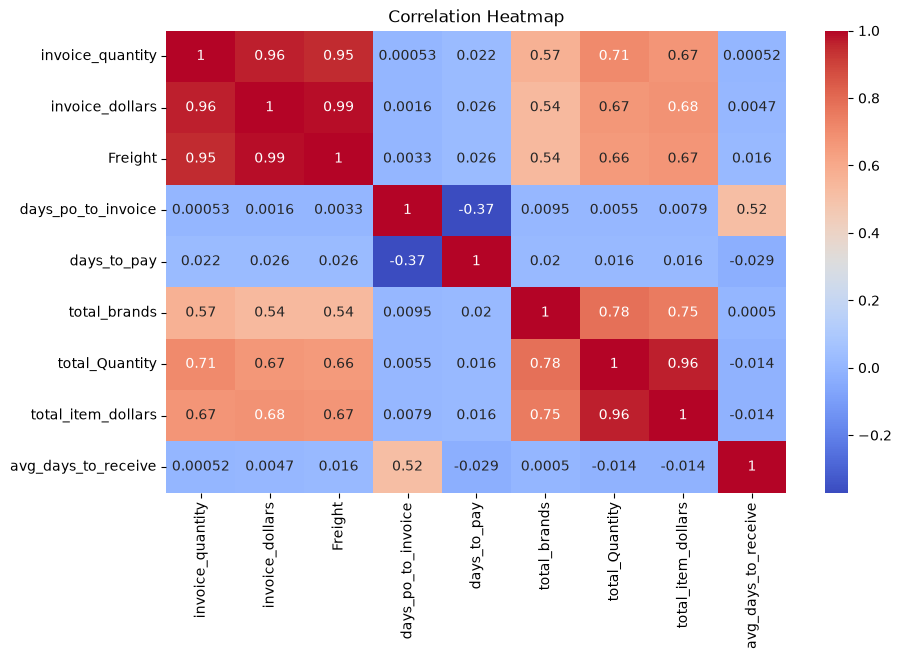

In [20]:
plt.figure(figsize=(10,6))
sns.heatmap(data.iloc[:,1:-1].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')

In [15]:
flagged_data = data[data['flag_invoice'] == 1]
normal_data = data[data['flag_invoice'] == 0]

In [16]:
significant_features = []
non_significant_features = []
results = []

meatrics = ['invoice_quantity', 'invoice_dollars', 'Freight', 'days_po_to_invoice', 'days_to_pay', 'total_brands', 'total_Quantity', 'total_item_dollars', 'avg_days_to_receive']


In [28]:
from scipy.stats import ttest_ind
for metric in meatrics:
    flagged_mean = flagged_data[metric].mean()
    normal_mean = normal_data[metric].mean()

    t_test, p_value = ttest_ind(
        flagged_data[metric].dropna(),
        normal_data[metric].dropna(),
        equal_var=False
    )

    if p_value < 0.05:
        significant_features.append(metric)
        results.append({
            'metric': metric,
            'flagged_mean': flagged_mean.__round__(2),
            'normal_mean': normal_mean.__round__(2),
            'p_value': p_value
        })
    else:
        non_significant_features.append(metric)

In [23]:
significant_features

['invoice_quantity',
 'invoice_dollars',
 'Freight',
 'days_po_to_invoice',
 'total_Quantity',
 'total_item_dollars',
 'avg_days_to_receive']

In [25]:
non_significant_features

['days_to_pay', 'total_brands']

In [30]:
results

[{'metric': 'invoice_quantity',
  'flagged_mean': np.float64(6728.28),
  'normal_mean': np.float64(5723.55),
  'p_value': np.float64(0.02130409456006982)},
 {'metric': 'invoice_dollars',
  'flagged_mean': np.float64(65600.61),
  'normal_mean': np.float64(54302.64),
  'p_value': np.float64(0.008046854812552177)},
 {'metric': 'Freight',
  'flagged_mean': np.float64(334.02),
  'normal_mean': np.float64(276.89),
  'p_value': np.float64(0.008176606234987472)},
 {'metric': 'days_po_to_invoice',
  'flagged_mean': np.float64(17.23),
  'normal_mean': np.float64(16.02),
  'p_value': np.float64(5.4501676475757507e-42)},
 {'metric': 'total_Quantity',
  'flagged_mean': np.float64(6728.28),
  'normal_mean': np.float64(5723.55),
  'p_value': np.float64(0.021304728687597314)},
 {'metric': 'total_item_dollars',
  'flagged_mean': np.float64(65600.61),
  'normal_mean': np.float64(54302.64),
  'p_value': np.float64(0.008046862507760823)},
 {'metric': 'avg_days_to_receive',
  'flagged_mean': np.float64(8.4

In [67]:
x= data[['invoice_quantity','invoice_dollars','Freight','total_Quantity','total_item_dollars','avg_days_to_receive']]
y= data['flag_invoice']

In [68]:
x.describe().round(2)

,invoice_quantity,invoice_dollars,Freight,total_Quantity,total_item_dollars,avg_days_to_receive
count,5543.00,5543.00,5543.00,5543.00,5543.00,5543.00
mean,6058.88,58073.38,295.95,6058.88,58073.38,7.67
std,14453.34,140234.03,713.59,14453.34,140234.03,1.82
min,1.00,4.14,0.02,1.00,4.14,3.00
25%,83.00,967.81,5.02,83.00,967.81,6.13
50%,423.00,4765.45,24.73,423.00,4765.45,7.74
75%,5100.50,44587.18,229.66,5100.50,44587.18,9.08
max,141660.00,1660435.88,8468.22,141660.00,1660435.88,13.00


In [75]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler , MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score, make_scorer, roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV




In [69]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)


In [70]:
model1 = LogisticRegression()
model1.fit(x_train_scaled, y_train)

model2 = DecisionTreeClassifier()
model2.fit(x_train_scaled, y_train)

model3 = RandomForestClassifier()
model3.fit(x_train_scaled, y_train)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [71]:
def evaluate_model(model , x_test_scaled, y_test,name):
    y_pred = model.predict(x_test_scaled)

    
    print(f"Model: {name}")
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))
    print('Accuracy:', model.score(x_test_scaled, y_test))
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))


In [72]:
evaluate_model(model1, x_test_scaled, y_test, "Logistic Regression")
evaluate_model(model2, x_test_scaled, y_test, "Decision Tree Classifier")
evaluate_model(model3, x_test_scaled, y_test, "Random Forest Classifier")

Model: Logistic Regression
Confusion Matrix:
[[674  51]
 [236 148]]
Accuracy: 0.7412082957619477

Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.93      0.82       725
           1       0.74      0.39      0.51       384

    accuracy                           0.74      1109
   macro avg       0.74      0.66      0.67      1109
weighted avg       0.74      0.74      0.71      1109

Model: Decision Tree Classifier
Confusion Matrix:
[[706  19]
 [ 34 350]]
Accuracy: 0.9522091974752029

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.97      0.96       725
           1       0.95      0.91      0.93       384

    accuracy                           0.95      1109
   macro avg       0.95      0.94      0.95      1109
weighted avg       0.95      0.95      0.95      1109

Model: Random Forest Classifier
Confusion Matrix:
[[725   0]
 [ 40 344]]
Accuracy: 0.96393146979260

In [73]:
model3.feature_importances_

array([0.11187507, 0.10855796, 0.09463066, 0.15620504, 0.21537226,
       0.313359  ])

In [74]:
for i in range(len(model3.feature_importances_)):
    print(f"Feature: {x.columns[i]}, Importance: {model3.feature_importances_[i]*100:.2f}%")

Feature: invoice_quantity, Importance: 11.19%
Feature: invoice_dollars, Importance: 10.86%
Feature: Freight, Importance: 9.46%
Feature: total_Quantity, Importance: 15.62%
Feature: total_item_dollars, Importance: 21.54%
Feature: avg_days_to_receive, Importance: 31.34%


In [76]:
parameter_grid ={
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 4, 5, 6],
    "min_samples_split": [2, 3, 5],
    "min_samples_leaf": [1, 2, 5],
    "criterion": ['gini', 'entropy']

}

In [77]:
rf= RandomForestClassifier(
    random_state=42,
    n_jobs=-1,
)
scorer = make_scorer(f1_score)
GridSearch = GridSearchCV(
    estimator=rf,
    param_grid=parameter_grid,
    scoring=scorer,
    cv=5,
    verbose=2,
    n_jobs=-1
)
GridSearch.fit(x_train_scaled, y_train)
evaluate_model(GridSearch.best_estimator_, x_test_scaled, y_test, "Random Forest Classifier with Grid Search")

Fitting 5 folds for each of 216 candidates, totalling 1080 fits
Model: Random Forest Classifier with Grid Search
Confusion Matrix:
[[725   0]
 [ 37 347]]
Accuracy: 0.9666366095581606

Classification Report:
              precision    recall  f1-score   support

           0       0.95      1.00      0.98       725
           1       1.00      0.90      0.95       384

    accuracy                           0.97      1109
   macro avg       0.98      0.95      0.96      1109
weighted avg       0.97      0.97      0.97      1109

